# Machine Learning Operations (MLOps) AIMLCZG523
## Assignment 01
### **Name**: Patil Sharyu Rupchand

### **BITS ID**: 2025ae05445


#### **Problem Statement**: Build a machine learning classifier to predict the risk of heart disease based on patient health data, and deploy the solution as a cloud-ready, monitored API

In [92]:
!pip install ucimlrepo

**1. Data Acquisition & Exploratory Data Analysis (EDA)**

In [93]:
!pip install ucimlrepo

In [94]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

In [95]:
import pandas as pd
import numpy as np

# -----------------------------
# 1. Load dataset from ucimlrepo
# -----------------------------
X = heart_disease.data.features
y = heart_disease.data.targets

df = pd.concat([X, y], axis=1)

print("Initial shape:", df.shape)
print(df.head())
print(df.info())

# -----------------------------
# 2. Handle missing values
# -----------------------------

# Check missing values
print("\nMissing values per column:")
print(df.isna().sum())

# Numeric columns → fill missing with median
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    df[col].fillna(df[col].median(), inplace=True)

# If any non-numeric missing remain → drop rows
df.dropna(inplace=True)

print("\nShape after handling missing values:", df.shape)

# -----------------------------
# 3. Encode target (binary classification)
# -----------------------------
# UCI 'num' column: 0 = no disease, 1–4 = disease
if "num" in df.columns:
    df["target"] = (df["num"] > 0).astype(int)
    df.drop(columns=["num"], inplace=True)

print("\nTarget value counts:")
print(df["target"].value_counts())

# -----------------------------
# 4. Encode categorical features
# -----------------------------
# These columns are categorical in UCI Heart dataset
categorical_cols = ["cp", "restecg", "thal", "slope"]

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("\nShape after encoding categorical features:", df.shape)

# -----------------------------
# 5. Final feature/target split
# -----------------------------
X = df.drop("target", axis=1)
y = df["target"]

print("\nFinal feature matrix shape:", X.shape)
print("Final target vector shape:", y.shape)
print("\nAfter Preprocessing:\n")
print(df.head())


Initial shape: (303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null  

/tmp/ipykernel_3851/913152214.py:28: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


<Figure size 1400x1000 with 0 Axes>

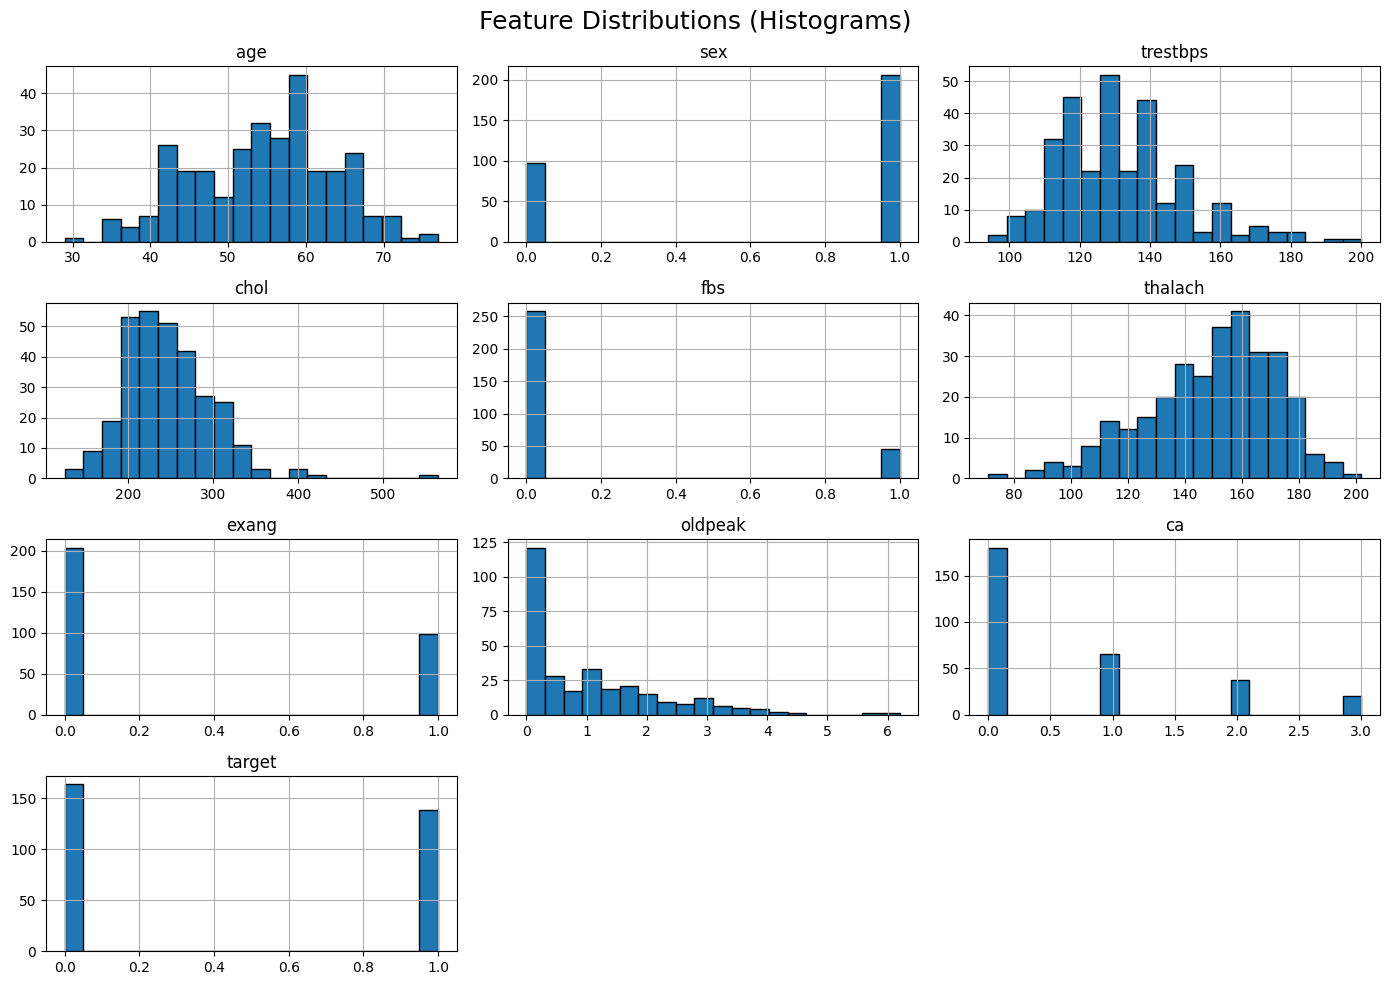

/tmp/ipykernel_3851/2207284094.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df["target"], palette="Set2")


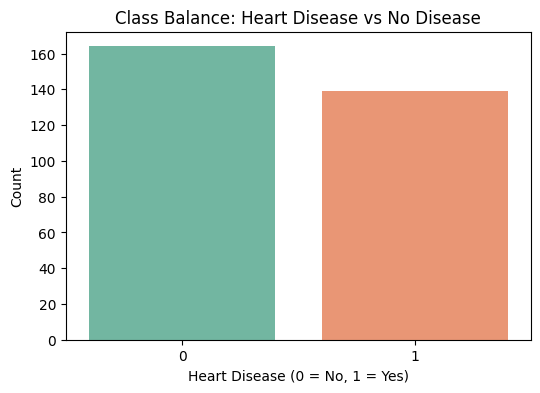

Class distribution:
target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


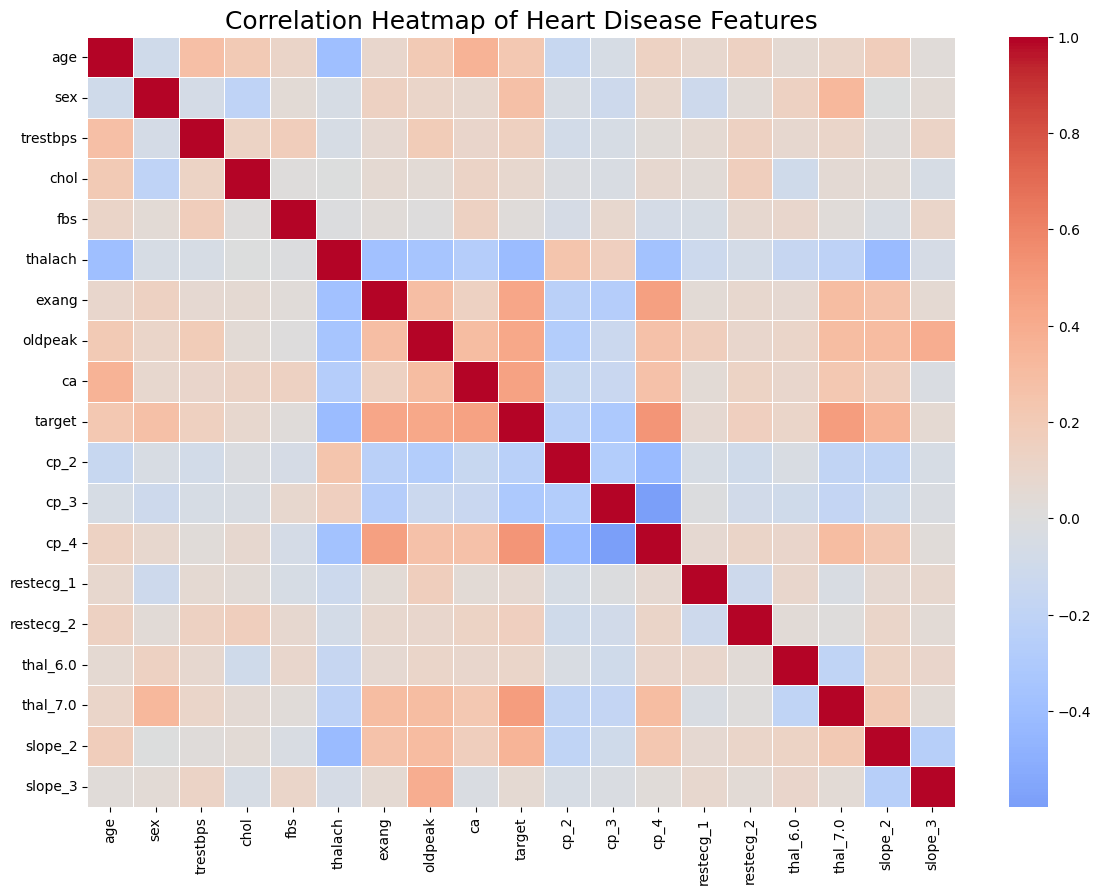


Correlation with target:
target       1.000000
cp_4         0.516459
thal_7.0     0.480582
ca           0.460033
exang        0.431894
oldpeak      0.424510
slope_2      0.355709
sex          0.276816
age          0.223120
restecg_2    0.160400
trestbps     0.150825
thal_6.0     0.104864
chol         0.085164
restecg_1    0.067605
slope_3      0.061710
fbs          0.025264
cp_2        -0.248683
cp_3        -0.315141
thalach     -0.417167
Name: target, dtype: float64


In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

#sns.set(style="whitegrid", context="talk")

# -----------------------------
# 1. Histograms of key features
# -----------------------------
plt.figure(figsize=(14, 10))
df.hist(figsize=(14, 10), bins=20, edgecolor='black')
plt.suptitle("Feature Distributions (Histograms)", fontsize=18)
plt.tight_layout()
plt.show()

# -----------------------------
# 2. Class balance visualization
# -----------------------------
plt.figure(figsize=(6, 4))
sns.countplot(x=df["target"], palette="Set2")
plt.title("Class Balance: Heart Disease vs No Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

print("Class distribution:")
print(df["target"].value_counts(normalize=True))

# -----------------------------
# 3. Correlation heatmap
# -----------------------------
plt.figure(figsize=(14, 10))
corr = df.corr()

sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Heart Disease Features", fontsize=18)
plt.show()

# Show correlation of each feature with target
print("\nCorrelation with target:")
print(corr["target"].sort_values(ascending=False))


**2. Feature Engineering & Model Development**

2.1 Feature Preparation + Model Training & Evaluation

In [98]:
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix, f1_score
import numpy as np

# Identify numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if "target" in numeric_cols:
    numeric_cols.remove("target")   # exclude target

# Identify all other columns (the one-hot encoded boolean/binary columns)
other_cols = [col for col in df.columns if col != "target" and col not in numeric_cols]

# Define the preprocessor explicitly mapping every feature to avoid internal remainder helpers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("passthrough", "passthrough", other_cols)
    ],
    remainder="drop"
)

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

log_reg_clf = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

log_reg_cv = cross_validate(
    log_reg_clf, X, y,
    cv=5,
    scoring=["accuracy", "precision", "recall", "roc_auc", "f1"],
    return_train_score=False
)

print("Logistic Regression CV Results:")
print("Accuracy:", log_reg_cv["test_accuracy"].mean())
print("Precision:", log_reg_cv["test_precision"].mean())
print("Recall:", log_reg_cv["test_recall"].mean())
print("ROC-AUC:", log_reg_cv["test_roc_auc"].mean())
print("F1:", log_reg_cv["test_f1"].mean())

rf_clf = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42
    ))
])

rf_cv = cross_validate(
    rf_clf, X, y,
    cv=5,
    scoring=["accuracy", "precision", "recall", "roc_auc", "f1"],
    return_train_score=False
)

print("\nRandom Forest CV Results:")
print("Accuracy:", rf_cv["test_accuracy"].mean())
print("Precision:", rf_cv["test_precision"].mean())
print("Recall:", rf_cv["test_recall"].mean())
print("ROC-AUC:", rf_cv["test_roc_auc"].mean())
print("F1:", rf_cv["test_f1"].mean())

Logistic Regression CV Results:
Accuracy: 0.8314754098360657
Precision: 0.8361999410386508
Recall: 0.7915343915343915
ROC-AUC: 0.9155072550905885
F1: 0.8103341680290832

Random Forest CV Results:
Accuracy: 0.834808743169399
Precision: 0.8346565447435011
Recall: 0.7986772486772488
ROC-AUC: 0.9044156846240181
F1: 0.8144735086256002


2.2 Final Model Fit + Test Set Evaluation

In [99]:
# Fit both models
log_reg_clf.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)

# Predictions
log_reg_pred = log_reg_clf.predict(X_test)
rf_pred = rf_clf.predict(X_test)

# Probabilities for ROC-AUC
log_reg_prob = log_reg_clf.predict_proba(X_test)[:, 1]
rf_prob = rf_clf.predict_proba(X_test)[:, 1]

print("\n--- Test Set Evaluation ---")

print("\nLogistic Regression:")
print("Accuracy:", accuracy_score(y_test, log_reg_pred))
print("Precision:", precision_score(y_test, log_reg_pred))
print("Recall:", recall_score(y_test, log_reg_pred))
print("ROC-AUC:", roc_auc_score(y_test, log_reg_prob))
print("F1:", f1_score(y_test, log_reg_pred))


print("\nRandom Forest:")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("F1:", f1_score(y_test, rf_pred))


--- Test Set Evaluation ---

Logistic Regression:
Accuracy: 0.8524590163934426
Precision: 0.8064516129032258
Recall: 0.8928571428571429
ROC-AUC: 0.9556277056277057
F1: 0.847457627118644

Random Forest:
Accuracy: 0.9344262295081968
Precision: 0.9
Recall: 0.9642857142857143
ROC-AUC: 0.9604978354978355
F1: 0.9310344827586207


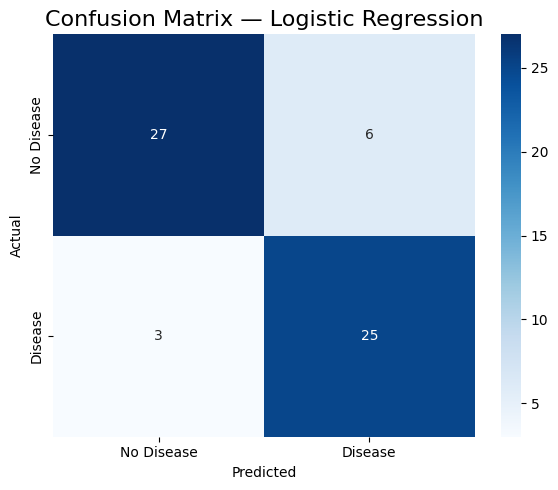

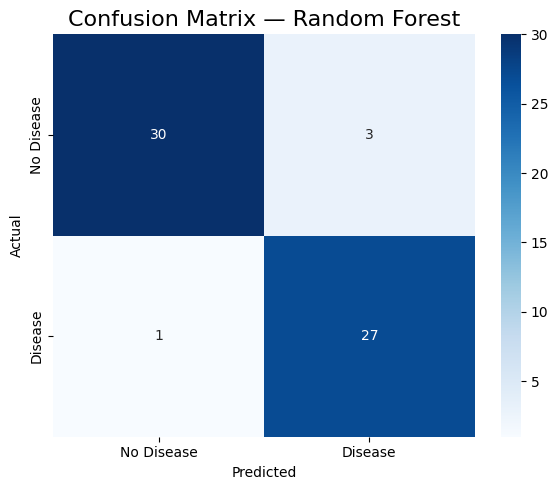

In [100]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Confusion Matrix Function
# -----------------------------
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No Disease", "Disease"],
                yticklabels=["No Disease", "Disease"])
    plt.title(title, fontsize=16)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# -----------------------------
# Logistic Regression Confusion Matrix
# -----------------------------
plot_confusion_matrix(y_test, log_reg_pred,
                      "Confusion Matrix — Logistic Regression")

# -----------------------------
# Random Forest Confusion Matrix
# -----------------------------
plot_confusion_matrix(y_test, rf_pred,
                      "Confusion Matrix — Random Forest")


2.3 Champion Model

In [101]:
champion_model = rf_clf
champion_model_name = "Random Forest"

print("Champion model:", champion_model_name)

Champion model: Random Forest


**3. Experiment Tracking**

In [78]:
!curl -LsSf https://astral.sh/uv/install.sh | sh

downloading uv 0.13.1 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!


In [102]:
!uv pip install --system mlflow

Using Python 3.13.16 environment at: /usr
Checked 1 package in 157ms


In [103]:
#from google.colab import drive
import os
from pathlib import Path

# Mount Google Drive
#drive.mount('/content/drive')

# Path to check
#PROJECT_ROOT = "/content/drive/MyDrive/MLOps/Heart_Disease_Detection"
PROJECT_ROOT = "/content/MLOps/Heart_Disease_Detection"

# Check if directory exists
if os.path.exists(PROJECT_ROOT):
    print("Directory exists:", PROJECT_ROOT)
else:
    print("Directory does NOT exist:", PROJECT_ROOT)

PROJECT_ROOT = Path(PROJECT_ROOT)
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

Directory exists: /content/MLOps/Heart_Disease_Detection


In [104]:
import mlflow
from pathlib import Path
from mlflow.tracking import MlflowClient

# 1. Define Paths
#PROJECT_ROOT = Path("/content/MLOps/Heart_Disease_Detection")
MLFLOW_DIR = PROJECT_ROOT / "MLflow"
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
MLFLOW_DB = MLFLOW_DIR / "mlflow.db"
MLFLOW_ARTIFACT_DIR = MLFLOW_DIR / "artifacts"
MLFLOW_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Configure URIs for Tracking and Model Registry
sqlite_uri = f"sqlite:///{MLFLOW_DB.resolve()}"
mlflow.set_tracking_uri(sqlite_uri)
mlflow.set_registry_uri(sqlite_uri)

# 3. Create or Fetch the Experiment explicitly connected to the URI
EXPERIMENT_NAME = "Heart Disease Detection"
client = MlflowClient(tracking_uri=sqlite_uri, registry_uri=sqlite_uri)

experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    experiment_id = client.create_experiment(
        name=EXPERIMENT_NAME,
        artifact_location=MLFLOW_ARTIFACT_DIR.as_uri()
    )
    print("Created a new MLflow experiment on SQLite backend.")
else:
    experiment_id = experiment.experiment_id
    print("Linked successfully to the existing SQLite-backed experiment.")

# 4. Set the Active Experiment for the current Python process
mlflow.set_experiment(EXPERIMENT_NAME)

# 5. Verify Configuration
print("Tracking URI:", mlflow.get_tracking_uri())
print("Registry URI:", mlflow.get_registry_uri())
print("Active Experiment ID:", experiment_id)
print("Artifact Location:", client.get_experiment(experiment_id).artifact_location)

Linked successfully to the existing SQLite-backed experiment.
Tracking URI: sqlite:////content/MLOps/Heart_Disease_Detection/MLflow/mlflow.db
Registry URI: sqlite:////content/MLOps/Heart_Disease_Detection/MLflow/mlflow.db
Active Experiment ID: 1
Artifact Location: file:///content/MLOps/Heart_Disease_Detection/MLflow/artifacts


In [105]:
import mlflow

exp = mlflow.get_experiment_by_name("Heart Disease Detection")
if exp is not None:
    print("Experiment Name:", exp.name)
    print("Artifact Location:", exp.artifact_location)

    # Fetch runs using experiment_id to ensure a reliable search
    runs = mlflow.search_runs(experiment_ids=[exp.experiment_id])

    print("Columns containing 'metrics':", [c for c in runs.columns if "metrics" in c])

    if not runs.empty:
        # Dynamically build columns list based on what is actually present in the DataFrame
        desired_cols = ["run_id", "tags.mlflow.runName", "params.model_type", "metrics.accuracy", "metrics.precision", "metrics.recall", "metrics.roc_auc", "metrics.f1_score"]
        existing_cols = [c for c in desired_cols if c in runs.columns]
        display(runs[existing_cols])
    else:
        print("No runs found in this experiment yet. Please check if your training runs were completed within the active experiment run blocks.")
else:
    print("Experiment not found.")

print("Experiment name:", exp.name)
print("Experiment ID:", exp.experiment_id)
print("Artifact location:", exp.artifact_location)

print("MLflow database exists:", MLFLOW_DB.exists())
print("MLflow database path:", MLFLOW_DB.resolve())

print("MLflow artifact directory exists:", MLFLOW_ARTIFACT_DIR.exists())
print("MLflow artifact directory:", MLFLOW_ARTIFACT_DIR.resolve())

print("\nExperiment artifact location:")
print(exp.artifact_location)

Experiment Name: Heart Disease Detection
Artifact Location: file:///content/MLOps/Heart_Disease_Detection/MLflow/artifacts
Columns containing 'metrics': ['metrics.f1_score', 'metrics.roc_auc', 'metrics.recall', 'metrics.precision', 'metrics.accuracy']


,run_id,tags.mlflow.runName,params.model_type,metrics.accuracy,metrics.precision,metrics.recall,metrics.roc_auc,metrics.f1_score
0,bfcfc62c10d1483b86a0824becf2daaa,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
1,314be684000e473a9cf30fada902c6b1,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
2,fb13de0b56c8426894640e6d48f08100,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
3,85c1a52178f34d958b0a018fba4c317a,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
4,721ca9bbf3954cabbf9db04bc876db8b,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
5,62747cbdcba34b2b9a0d6b8975f76e34,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
6,90e88699770a4d6e90a045bc7343f382,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
7,1d492a2431754a568ab998187e488010,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
8,fac04ea495e04cd49be7c72982fb7faa,Random Forest,Random Forest,0.934426,0.900000,0.964286,0.960498,0.931034
9,debadea5892443ff8b915ff99a81bee1,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458


Experiment name: Heart Disease Detection
Experiment ID: 1
Artifact location: file:///content/MLOps/Heart_Disease_Detection/MLflow/artifacts
MLflow database exists: True
MLflow database path: /content/MLOps/Heart_Disease_Detection/MLflow/mlflow.db
MLflow artifact directory exists: True
MLflow artifact directory: /content/MLOps/Heart_Disease_Detection/MLflow/artifacts

Experiment artifact location:
file:///content/MLOps/Heart_Disease_Detection/MLflow/artifacts


3.1 Configure MLflow

In [106]:
import sklearn
import mlflow
print(sklearn.__version__)
print(mlflow.__version__)
print(sklearn.compose._column_transformer._RemainderColsList)

1.6.1
3.17.1
<class 'sklearn.compose._column_transformer._RemainderColsList'>


In [107]:
import mlflow
import mlflow.sklearn
import sklearn

with mlflow.start_run(run_name="Logistic Regression (skops)"):

    # Log parameters
    mlflow.log_param("model_type", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)

    # Log metrics
    mlflow.log_metric("accuracy", accuracy_score(y_test, log_reg_pred))
    mlflow.log_metric("precision", precision_score(y_test, log_reg_pred))
    mlflow.log_metric("recall", recall_score(y_test, log_reg_pred))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, log_reg_prob))
    mlflow.log_metric("f1_score", f1_score(y_test, log_reg_pred))

    # Log model using skops
    mlflow.sklearn.log_model(
        sk_model=log_reg_clf,
        artifact_path="model",
        registered_model_name="LogisticRegressionModel",
        #skops_trusted_types=['sklearn', 'sklearn.compose._column_transformer._RemainderColsList']
        skops_trusted_types=['sklearn.compose._column_transformer._RemainderColsList']
    )

print("Logistic Regression MLflow run completed successfully.")


2026/10/18 04:25:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logistic Regression MLflow run completed successfully.


Registered model 'LogisticRegressionModel' already exists. Creating a new version of this model...
Created version '6' of model 'LogisticRegressionModel'.


In [108]:
with mlflow.start_run(run_name="Random Forest"):
    mlflow.log_param("model_type", "Random Forest")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("n_jobs", -1)

    mlflow.log_metric("accuracy", accuracy_score(y_test, rf_pred))
    mlflow.log_metric("precision", precision_score(y_test, rf_pred))
    mlflow.log_metric("recall", recall_score(y_test, rf_pred))
    mlflow.log_metric("roc_auc", roc_auc_score(y_test, rf_prob))
    mlflow.log_metric("f1_score", f1_score(y_test, rf_pred))

    # Explicitly trust the internal classes to allow skops serialization
    mlflow.sklearn.log_model(
        sk_model=rf_clf,
        artifact_path="model",
        skops_trusted_types=[
            'sklearn.compose._column_transformer._RemainderColsList',
            'sklearn.tree._tree.Tree'
        ]
    )

print("Random Forest MLflow run completed.")

2026/10/18 04:26:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Random Forest MLflow run completed.


In [109]:
runs = mlflow.search_runs(experiment_names=["Heart Disease Detection"])

display(runs[["run_id", "tags.mlflow.runName", "params.model_type", "metrics.accuracy", "metrics.precision", "metrics.recall", "metrics.roc_auc", "metrics.f1_score"]])

,run_id,tags.mlflow.runName,params.model_type,metrics.accuracy,metrics.precision,metrics.recall,metrics.roc_auc,metrics.f1_score
0,d5fecd6532dc42dba659422198308544,Random Forest,Random Forest,0.934426,0.900000,0.964286,0.960498,0.931034
1,95bb316f8f03499c82df7a0311183c41,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
2,bfcfc62c10d1483b86a0824becf2daaa,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
3,314be684000e473a9cf30fada902c6b1,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
4,fb13de0b56c8426894640e6d48f08100,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
5,85c1a52178f34d958b0a018fba4c317a,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
6,721ca9bbf3954cabbf9db04bc876db8b,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
7,62747cbdcba34b2b9a0d6b8975f76e34,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
8,90e88699770a4d6e90a045bc7343f382,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458
9,1d492a2431754a568ab998187e488010,Logistic Regression (skops),Logistic Regression,0.852459,0.806452,0.892857,0.955628,0.847458


In [110]:
valid_runs = runs.dropna(subset=["metrics.accuracy", "metrics.precision", "metrics.recall", "metrics.roc_auc", "metrics.f1_score"]).copy()

display(valid_runs[["run_id", "tags.mlflow.runName", "metrics.accuracy", "metrics.precision", "metrics.recall", "metrics.roc_auc", "metrics.f1_score"]])

,run_id,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.roc_auc,metrics.f1_score
0,d5fecd6532dc42dba659422198308544,Random Forest,0.934426,0.900000,0.964286,0.960498,0.931034
1,95bb316f8f03499c82df7a0311183c41,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
2,bfcfc62c10d1483b86a0824becf2daaa,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
3,314be684000e473a9cf30fada902c6b1,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
4,fb13de0b56c8426894640e6d48f08100,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
5,85c1a52178f34d958b0a018fba4c317a,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
6,721ca9bbf3954cabbf9db04bc876db8b,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
7,62747cbdcba34b2b9a0d6b8975f76e34,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
8,90e88699770a4d6e90a045bc7343f382,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458
9,1d492a2431754a568ab998187e488010,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458


In [111]:
tracked_comparison = valid_runs[["run_id", "tags.mlflow.runName", "metrics.accuracy", "metrics.precision", "metrics.recall", "metrics.roc_auc", "metrics.f1_score"]].copy()

tracked_comparison = tracked_comparison.drop_duplicates(
    subset=["tags.mlflow.runName"],
    keep="first"
)

tracked_comparison = tracked_comparison.rename(
    columns={
        "tags.mlflow.runName": "Model",
        "metrics.accuracy": "Accuracy",
        "metrics.precision": "Precision",
        "metrics.recall": "Recall",
        "metrics.roc_auc": "ROC-AUC",
        "metrics.f1_score": "F1 Score",
    }
)

display(tracked_comparison)

,run_id,Model,Accuracy,Precision,Recall,ROC-AUC,F1 Score
0,d5fecd6532dc42dba659422198308544,Random Forest,0.934426,0.900000,0.964286,0.960498,0.931034
1,95bb316f8f03499c82df7a0311183c41,Logistic Regression (skops),0.852459,0.806452,0.892857,0.955628,0.847458


In [112]:
champion_run = tracked_comparison.loc[tracked_comparison["F1 Score"].idxmax()]

print("MLflow champion model:", champion_run["Model"])
print("Champion run ID:", champion_run["run_id"])
print("Champion F1 Score:", champion_run["F1 Score"])

MLflow champion model: Random Forest
Champion run ID: d5fecd6532dc42dba659422198308544
Champion F1 Score: 0.9310344827586207


In [113]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR.resolve())

Model directory: /content/models


In [114]:
FEATURE_COLUMNS = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
]

In [115]:
import joblib

champion_model = rf_clf
champion_model_name = "Random Forest"

joblib.dump(champion_model, MODEL_DIR / "champion_model.pkl")
joblib.dump(FEATURE_COLUMNS, MODEL_DIR / "feature_columns.pkl")

print("Champion model:", champion_model_name)
print("Champion model saved to:", MODEL_DIR / "champion_model.pkl")
print("Feature list saved to:", MODEL_DIR / "feature_columns.pkl")

Champion model: Random Forest
Champion model saved to: models/champion_model.pkl
Feature list saved to: models/feature_columns.pkl


In [116]:
import joblib

loaded_champion_model = joblib.load(MODEL_DIR / "champion_model.pkl")
loaded_feature_columns = joblib.load(MODEL_DIR / "feature_columns.pkl")

print("Loaded model type:", type(loaded_champion_model).__name__)
print("Number of feature columns:", len(loaded_feature_columns))
print("Feature columns match:", loaded_feature_columns == FEATURE_COLUMNS)

Loaded model type: Pipeline
Number of feature columns: 13
Feature columns match: True


In [60]:
ARTIFACT_DIR = PROJECT_ROOT / "Artifacts"

In [117]:
DRIVE_ARTIFACT_DIR = PROJECT_ROOT / "Artifacts"
DRIVE_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(loaded_champion_model, DRIVE_ARTIFACT_DIR / "champion_model.pkl")
joblib.dump(loaded_feature_columns, DRIVE_ARTIFACT_DIR / "feature_columns.pkl")

print("Champion model saved to:", DRIVE_ARTIFACT_DIR / "champion_model.pkl")
print("Feature list saved to:", DRIVE_ARTIFACT_DIR / "feature_columns.pkl")


Champion model saved to: /content/MLOps/Heart_Disease_Detection/Artifacts/champion_model.pkl
Feature list saved to: /content/MLOps/Heart_Disease_Detection/Artifacts/feature_columns.pkl


In [118]:
import os

print("MLflow export directory:")
print(MLFLOW_DIR.resolve())

print("\nContents:")

for path in sorted(MLFLOW_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(MLFLOW_DIR))

MLflow export directory:
/content/MLOps/Heart_Disease_Detection/MLflow

Contents:
artifacts/models/m-0ec136895ebe4e6dac4118d7b22c486d/artifacts/MLmodel
artifacts/models/m-0ec136895ebe4e6dac4118d7b22c486d/artifacts/conda.yaml
artifacts/models/m-0ec136895ebe4e6dac4118d7b22c486d/artifacts/model.skops
artifacts/models/m-0ec136895ebe4e6dac4118d7b22c486d/artifacts/python_env.yaml
artifacts/models/m-0ec136895ebe4e6dac4118d7b22c486d/artifacts/requirements.txt
artifacts/models/m-249b92473db64203bf7f6fbaddb3ebfa/artifacts/MLmodel
artifacts/models/m-249b92473db64203bf7f6fbaddb3ebfa/artifacts/conda.yaml
artifacts/models/m-249b92473db64203bf7f6fbaddb3ebfa/artifacts/model.skops
artifacts/models/m-249b92473db64203bf7f6fbaddb3ebfa/artifacts/python_env.yaml
artifacts/models/m-249b92473db64203bf7f6fbaddb3ebfa/artifacts/requirements.txt
artifacts/models/m-4609e326939142ebbbb2bb405872e83a/artifacts/MLmodel
artifacts/models/m-4609e326939142ebbbb2bb405872e83a/artifacts/conda.yaml
artifacts/models/m-4609e326

In [119]:
import shutil

MLFLOW_EXPORT_ZIP = PROJECT_ROOT / "MLflow_export"

shutil.make_archive(
    base_name=str(MLFLOW_EXPORT_ZIP),
    format="zip",
    root_dir=MLFLOW_DIR.parent,
    base_dir=MLFLOW_DIR.name
)

print("MLflow export package created:")
print(f"{MLFLOW_EXPORT_ZIP}.zip")

MLflow export package created:
/content/MLOps/Heart_Disease_Detection/MLflow_export.zip


In [120]:
from google.colab import files

files.download(str(MLFLOW_EXPORT_ZIP) + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [121]:
from pathlib import Path
import joblib
import pandas as pd

MODEL_DIR = Path("models")

print("Model directory:", MODEL_DIR.resolve())

Model directory: /content/models


In [122]:
INPUT_FEATURES = loaded_feature_columns

print("Prediction input features:")
for index, feature in enumerate(INPUT_FEATURES, start=1):
    print(f"{index}. {feature}")

Prediction input features:
1. age
2. sex
3. cp
4. trestbps
5. chol
6. fbs
7. restecg
8. thalach
9. exang
10. oldpeak
11. slope
12. ca
13. thal


In [35]:
def predict_bot(features):
    input_data = pd.DataFrame([features], columns=INPUT_FEATURES)
    prediction = loaded_champion_model.predict(input_data)[0]
    return prediction

print("Prediction function created successfully.")

Prediction function created successfully.
